In [40]:
import pandas as pd
import joblib

X_train = pd.read_csv("../data/X_train_encoded_new.csv")
X_test = pd.read_csv("../data/X_test_encoded_new.csv")

Y_train = pd.read_csv("../data/Y_train_new.csv").squeeze("columns")
Y_test = pd.read_csv("../data/Y_test_new.csv").squeeze("columns")

In [41]:
X_train

,Age_Group,Social_Media_Hours,Social_Media_Scam_Exposure,Personal_Social_Media_Fraud_Loss,Transaction_Fraud_Loss,OTP_Password_Request_Exposure,Suspicious_Link_Clicks
0,2,0,0,1,0,2,2
1,0,3,0,0,1,0,1
2,0,1,0,0,0,1,1
3,1,1,4,0,0,4,0
4,2,4,2,1,0,4,1
...,...,...,...,...,...,...,...
1202,2,3,3,1,0,0,3
1203,1,2,2,1,0,0,1
1204,0,0,2,0,0,1,0
1205,3,3,2,0,0,3,2


In [42]:
Y_train

0       0
1       0
2       1
3       1
4       1
       ..
1202    1
1203    1
1204    0
1205    1
1206    1
Name: Overall_Cybersecurity_Awareness, Length: 1207, dtype: int64

### Over sampling

In [43]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_resampled, Y_train_resampled = ros.fit_resample(X_train, Y_train)

In [44]:
X_train_resampled.shape

(1614, 7)

In [45]:
Y_train_resampled.shape

(1614,)

### Baseline model

In [46]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_resampled, Y_train_resampled)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [47]:
y_pred = model.predict(X_test)

In [48]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [49]:
print(f"Training accuracy: {model.score(X_train_resampled,Y_train_resampled)*100}")

Training accuracy: 51.79677819083024


In [50]:
print(f"Testing accuracy: {accuracy_score(Y_test,y_pred)*100}")

Testing accuracy: 49.668874172185426


In [51]:
lr_accuracy=accuracy_score(Y_test, y_pred)
print("Accuracy (Logistic Regression):", lr_accuracy)
lr_report=classification_report(Y_test, y_pred)
print(lr_report)
lr_matrix=confusion_matrix(Y_test, y_pred)
print(lr_matrix)

Accuracy (Logistic Regression): 0.4966887417218543
              precision    recall  f1-score   support

           0       0.33      0.51      0.40       100
           1       0.67      0.49      0.57       202

    accuracy                           0.50       302
   macro avg       0.50      0.50      0.48       302
weighted avg       0.56      0.50      0.51       302

[[ 51  49]
 [103  99]]


In [52]:
from sklearn.ensemble import RandomForestClassifier
model2=RandomForestClassifier(n_estimators=300,random_state=42)
model2.fit(X_train_resampled,Y_train_resampled)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [53]:
y_pred2=model2.predict(X_test)

In [54]:
print(f"Training accuracy: {model2.score(X_train_resampled,Y_train_resampled)*100}")

Training accuracy: 93.80421313506815


In [55]:
print(f"Testing accuracy: {accuracy_score(Y_test,y_pred2)*100}")

Testing accuracy: 55.29801324503312


In [56]:
rf_accuracy=accuracy_score(Y_test, y_pred2)
print("Accuracy (Random Forest):", rf_accuracy)
rf_report=classification_report(Y_test, y_pred2)
print(rf_report)
rf_matrix=confusion_matrix(Y_test, y_pred2)
print(rf_matrix)

Accuracy (Random Forest): 0.5529801324503312
              precision    recall  f1-score   support

           0       0.30      0.26      0.28       100
           1       0.66      0.70      0.68       202

    accuracy                           0.55       302
   macro avg       0.48      0.48      0.48       302
weighted avg       0.54      0.55      0.54       302

[[ 26  74]
 [ 61 141]]


In [57]:
from sklearn.svm import SVC
model3=SVC()

In [58]:
model3.fit(X_train_resampled, Y_train_resampled)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [59]:
print(f"Training accuracy: {model3.score(X_train_resampled,Y_train_resampled)*100}")

Training accuracy: 61.957868649318456


In [60]:
y_pred3 = model3.predict(X_test)

In [61]:
print(f"Testing accuracy: {accuracy_score(Y_test,y_pred)*100}")

Testing accuracy: 49.668874172185426


In [62]:
svc_accuracy=accuracy_score(Y_test, y_pred3)
print("Accuracy (SVC):", svc_accuracy)
svc_report=classification_report(Y_test, y_pred3)
print(svc_report)
svc_matrix=confusion_matrix(Y_test, y_pred3)
print(svc_matrix)

Accuracy (SVC): 0.49337748344370863
              precision    recall  f1-score   support

           0       0.28      0.33      0.30       100
           1       0.63      0.57      0.60       202

    accuracy                           0.49       302
   macro avg       0.46      0.45      0.45       302
weighted avg       0.52      0.49      0.50       302

[[ 33  67]
 [ 86 116]]


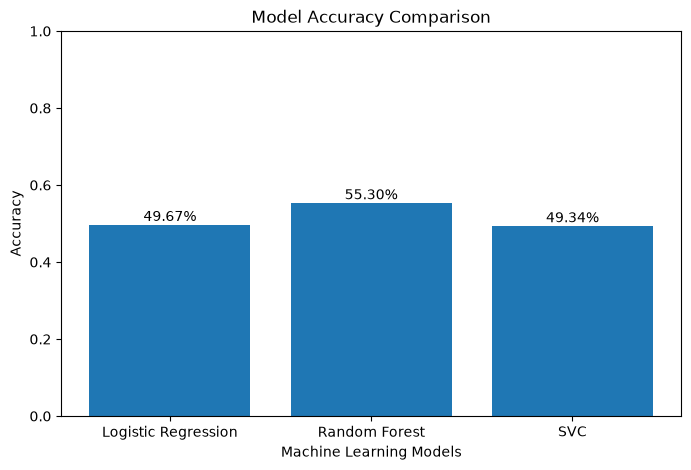

In [63]:
import matplotlib.pyplot as plt

models = ['Logistic Regression', 'Random Forest', 'SVC']
accuracies = [lr_accuracy,rf_accuracy, svc_accuracy]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

# Display accuracy values above each bar
for i, accuracy in enumerate(accuracies):
    plt.text(i, accuracy + 0.01, f'{accuracy:.2%}', ha='center')

plt.show()

### currently random Fores has highest accuracy but has overfitting, So selected model is SVC.

## Hyperparameter Tuning

In [68]:
from sklearn.model_selection import GridSearchCV

In [69]:
param_grid= {
    'C': range(0,4,1),
    'gamma':range(1,25,1),
    'kernel':['linear','polynomial','rbf']
}

n_folds=10
model4=SVC()
grid_search=GridSearchCV(estimator=model4,param_grid=param_grid,cv=n_folds)

In [70]:
grid_search.fit(X_train_resampled,Y_train_resampled)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': range(0, 4), 'gamma': range(1, 25), 'kernel': ['linear', 'polynomial', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information 

In [71]:
grid_search.best_estimator_

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",3
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [72]:
grid_search.best_params_

{'C': 1, 'gamma': 3, 'kernel': 'rbf'}

In [73]:
model5=SVC(C=1,gamma=3,kernel="rbf")

In [74]:
model5.fit(X_train_resampled,Y_train_resampled)
print(f"Training accuracy: {model5.score(X_train_resampled,Y_train_resampled)*100}")

Training accuracy: 93.80421313506815


In [75]:
y_pred5 = model5.predict(X_test)

In [76]:
print(f"Testing accuracy: {accuracy_score(Y_test,y_pred5)*100}")

Testing accuracy: 63.576158940397356


## K-fold cross validation

In [77]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

In [78]:
kfold=KFold(n_splits=20)

In [79]:
x=pd.concat([X_train_resampled,X_test],axis=0)
y=pd.concat([Y_train_resampled,Y_test],axis=0)

In [80]:
x

,Age_Group,Social_Media_Hours,Social_Media_Scam_Exposure,Personal_Social_Media_Fraud_Loss,Transaction_Fraud_Loss,OTP_Password_Request_Exposure,Suspicious_Link_Clicks
0,2,0,0,1,0,2,2
1,0,3,0,0,1,0,1
2,0,1,0,0,0,1,1
3,1,1,4,0,0,4,0
4,2,4,2,1,0,4,1
...,...,...,...,...,...,...,...
297,0,2,3,0,1,0,2
298,0,4,0,1,1,0,1
299,4,1,0,0,0,0,0
300,1,4,4,0,0,3,1


In [81]:
y

0      0
1      0
2      1
3      1
4      1
      ..
297    1
298    1
299    1
300    1
301    1
Name: Overall_Cybersecurity_Awareness, Length: 1916, dtype: int64

In [82]:
results=cross_val_score(model5,x,y,scoring='accuracy',cv=kfold)

In [83]:
print(f"Final Accuracy:{results.mean()*100}")

Final Accuracy:78.47916666666666


In [86]:
from sklearn.metrics import accuracy_score, classification_report

model5.fit(X_train_resampled, Y_train_resampled)

y_pred5 = model5.predict(X_test)

test_accuracy = accuracy_score(Y_test, y_pred5)

print(f"Final Testing Accuracy: {test_accuracy * 100:.2f}%")
print(classification_report(Y_test, y_pred5))

joblib.dump(model5, "../models/model.pkl")

Final Testing Accuracy: 63.58%
              precision    recall  f1-score   support

           0       0.35      0.12      0.18       100
           1       0.67      0.89      0.77       202

    accuracy                           0.64       302
   macro avg       0.51      0.51      0.47       302
weighted avg       0.57      0.64      0.57       302



['../models/model.pkl']